# Strefy zarządzania NDVI (K-Means + normalizacja z-score w granicach pól)

Pipeline zgodny z założeniami Modułu 1:
1. Wybór pól o powierzchni `>= 3 ha` oraz bufor wewnętrzny `10 m` (odrzucenie pikseli brzegowych).
2. Normalizacja **z-score** wartości NDVI osobno dla każdej sceny i każdego pola.
3. Mediana czasowa ze znormalizowanych scen NDVI.
4. Uczenie nienadzorowane metodą **K-Means** (`k = 3`: strefa `1 = slaba`, `2 = srednia`, `3 = mocna`).
5. Filtr większościowy `3x3` usuwający izolowane piksele.
6. Wektoryzacja w `EPSG:2180` oraz scalanie fragmentów `< 0.3 ha` z sąsiednią strefą.

In [1]:
from pathlib import Path
from ndvi_kmeans import load_kmeans_model, process_fields_ndvi_kmeans
from ndvi_downloader import download_clip_sentinel_ndvi
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import rasterio

BOUNDARY_FILE = Path("test/fields.geojson")
NDVI_DIR = Path("test/ndvi")
OUT_DIR = Path("test/zones")
MODEL_PATH = OUT_DIR / "ndvi_kmeans_model.joblib"
START_DATE = "2024-03-01"
END_DATE = "2024-06-30"
N_SCENES = 8
N_CLUSTERS = 3

In [2]:
existing_tifs = sorted(NDVI_DIR.glob("*.tif")) if NDVI_DIR.exists() else []
if not existing_tifs:
    download_clip_sentinel_ndvi(
        boundary_file=BOUNDARY_FILE,
        start_date=START_DATE,
        end_date=END_DATE,
        out_dir=NDVI_DIR,
        max_cc=20,
        n_scenes=N_SCENES,
    )
else:
    print(f"Znaleziono {len(existing_tifs)} lokalnych scen NDVI w {NDVI_DIR}")

   Zapisano (1/8): ndvi_2024-05-14_S2A_33UWU_20240514_0_L2A.tif | braki: 0.0%
   Zapisano (2/8): ndvi_2024-03-08_S2A_33UWU_20240308_0_L2A.tif | braki: 0.0%
   Zapisano (3/8): ndvi_2024-05-17_S2A_33UWU_20240517_0_L2A.tif | braki: 0.0%
   Zapisano (4/8): ndvi_2024-03-30_S2B_33UWU_20240330_0_L2A.tif | braki: 0.0%
   Zapisano (5/8): ndvi_2024-06-26_S2A_33UWU_20240626_0_L2A.tif | braki: 0.0%
   Zapisano (6/8): ndvi_2024-05-02_S2B_33UWU_20240502_0_L2A.tif | braki: 0.0%
Uwaga: udało się znaleźć tylko 6 z 8 wymaganych scen.


In [3]:
zones_gdf = process_fields_ndvi_kmeans(
    boundary_file=BOUNDARY_FILE,
    ndvi_dir=NDVI_DIR,
    out_dir=OUT_DIR,
    n_clusters=N_CLUSTERS,
    inner_buffer_m=10.0,
    min_area_ha=3.0,
    min_zone_area_ha=0.3,
    apply_majority_filter=True,
    save_rasters=True,
    model_path=MODEL_PATH,
)

display(
    zones_gdf.groupby(["zone", "zone_label"])
    .agg(
        polygons=("area_ha", "count"),
        total_area_ha=("area_ha", "sum"),
        mean_ndvi_z=("ndvi_z", "mean"),
    )
    .round(3)
)
zones_gdf.head()

,,polygons,total_area_ha,mean_ndvi_z
zone,zone_label,,,
1,slaba,82,168.237,-1.073
2,srednia,140,219.922,-0.126
3,mocna,114,261.263,0.789


,field_id,zone,zone_label,area_ha,ndvi_z,geometry
0,1,3,mocna,0.9905,1.1580,"POLYGON ((281125.092 535881.646, 281124.537 53..."
1,1,1,slaba,1.2006,-1.2324,"POLYGON ((281296.538 535902.173, 281295.983 53..."
2,1,2,srednia,2.4613,0.1382,"POLYGON ((281254.367 535684.121, 281224.406 53..."
3,2,1,slaba,0.3102,-1.0509,"POLYGON ((282755.759 535480.479, 282754.649 53..."
4,2,2,srednia,0.4302,-0.0693,"POLYGON ((282714.146 535452.737, 282724.133 53..."


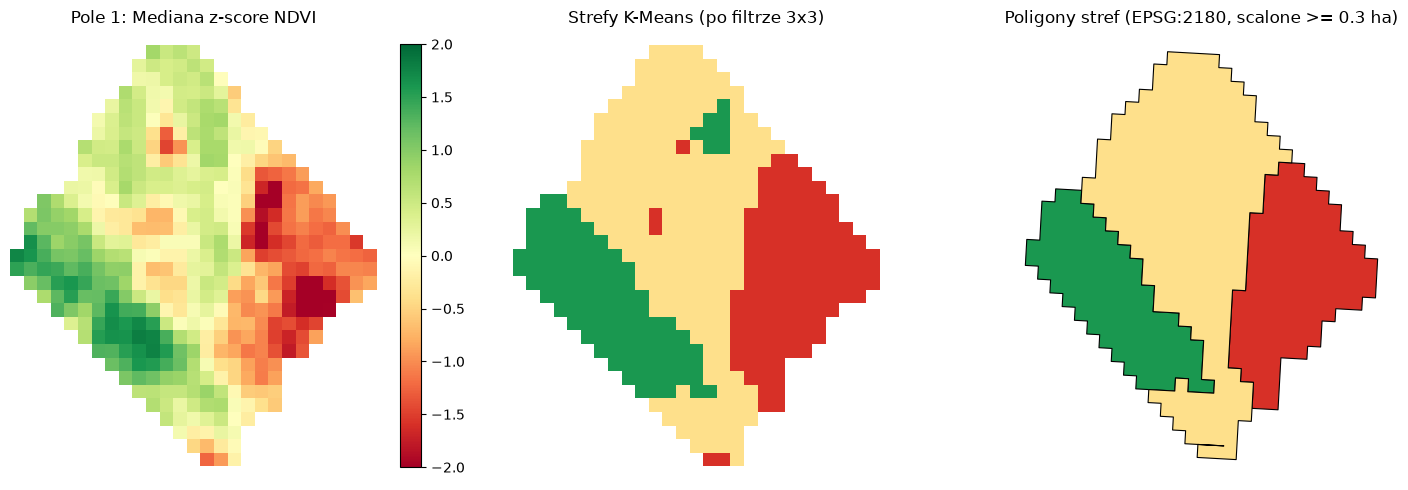

In [4]:
if not zones_gdf.empty:
    sample_field_id = zones_gdf["field_id"].iloc[0]
    field_polys = zones_gdf[zones_gdf["field_id"] == sample_field_id]

    ndvi_z_tif = OUT_DIR / "rasters" / f"field_{sample_field_id}_ndvi_z.tif"
    zones_tif = OUT_DIR / "rasters" / f"field_{sample_field_id}_zones.tif"

    with rasterio.open(ndvi_z_tif) as src_z, rasterio.open(zones_tif) as src_c:
        arr_z = src_z.read(1)
        arr_c = src_c.read(1).astype(float)
        arr_c[arr_c == 0] = np.nan

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    im0 = axes[0].imshow(arr_z, cmap="RdYlGn", vmin=-2, vmax=2)
    axes[0].set_title(f"Pole {sample_field_id}: Mediana z-score NDVI")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    zone_cmap = ListedColormap(["#d73027", "#fee08b", "#1a9850"])
    axes[1].imshow(arr_c, cmap=zone_cmap, vmin=1, vmax=3, interpolation="nearest")
    axes[1].set_title("Strefy K-Means (po filtrze 3x3)")

    color_map = {1: "#d73027", 2: "#fee08b", 3: "#1a9850"}
    field_polys.plot(
        ax=axes[2],
        color=field_polys["zone"].map(color_map),
        edgecolor="black",
        linewidth=0.8,
    )
    axes[2].set_title("Poligony stref (EPSG:2180, scalone >= 0.3 ha)")

    for ax in axes:
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [ ]:
# Wczytanie zapisanego modelu K-Means i podglad centroidow z-score
kmeans_model = load_kmeans_model(MODEL_PATH)
print(f"Zapisany model: {MODEL_PATH.resolve()}")
print("Centroidy z-score (1=slaba, 2=srednia, 3=mocna):", kmeans_model.cluster_centers_.ravel().round(4))